# 04 - Model Training

This notebook trains LSTM and GRU models on each feature group.

## Objectives
- Train models with default hyperparameters
- Monitor training progress
- Save trained models and checkpoints
- Compare training across feature groups

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Get project root (temporary, before importing src)
project_root = Path.cwd().parent  # Assuming notebook is in notebooks/ subfolder

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.config import get_project_root
# Now we can use the proper method if needed, but we already have it
# project_root = get_project_root()  # Uncomment if you want to verify

from src.utils.config import Config
from src.utils.seed import set_seed
from src.models.lstm import LSTMForecaster
from src.models.gru import GRUForecaster
from src.training.callbacks import get_callbacks
from src.evaluation.plots import plot_training_history

# TensorFlow setup
import tensorflow as tf
import logging
from tqdm import tqdm

logging.basicConfig(level=logging.INFO)

print(f"TensorFlow: {tf.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

if not tf.config.list_physical_devices('GPU'):
    print("Warning: No GPU detected; training may be slow.")

%matplotlib inline

TensorFlow: 2.20.0
GPUs: []


In [2]:
# Configuration
config = Config.load()

if not hasattr(config, 'assets') or not config.assets or not hasattr(config, 'model_configs') or not config.model_configs:
    raise RuntimeError("Config loading failed; check YAML files in configs/.")

assets = config.get_all_assets()
seeds = config.base.get('seeds', [42])  # Load all seeds from config

if not isinstance(seeds, list) or not all(isinstance(s, int) for s in seeds):
    raise ValueError("seeds in base.yaml must be a list of integers")

EPOCHS = config.base.get('epochs', 100)
BATCH_SIZE = config.base.get('batch_size', 64)

print(f"Assets: {assets}")
print(f"Seeds: {seeds}")
print(f"Total experiments: {len(assets)} assets × {len(seeds)} seeds = {len(assets) * len(seeds)} per model/group")

Assets: ['crudeoil', 'gold', 'bitcoin', 'ethereum', 'apple', 'microsoft', 'eurusd', 'usdjpy', 'nasdaq', 'sp500']
Seeds: [42, 123, 456, 739, 1126]
Total experiments: 10 assets × 5 seeds = 50 per model/group


In [3]:
# Load default hyperparameters
lstm_params = config.model_configs.get('lstm', {})
gru_params = config.model_configs.get('gru', {})

print("LSTM Parameters:")
for k, v in lstm_params.items():
    print(f"  {k}: {v}")

print("\nGRU Parameters:")
for k, v in gru_params.items():
    print(f"  {k}: {v}")

LSTM Parameters:
  architecture: {'layers': [{'type': 'lstm', 'units': 64, 'return_sequences': True, 'dropout': 0.05, 'recurrent_dropout': 0.0}, {'type': 'lstm', 'units': 64, 'return_sequences': False, 'dropout': 0.05, 'recurrent_dropout': 0.0}], 'dense_layers': [{'units': 32, 'activation': 'relu', 'dropout': 0.0}], 'output': {'units': 1, 'activation': 'linear'}}
  training: {'optimizer': {'learning_rate': 0.0001, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07}, 'loss': 'mse', 'metrics': ['mae']}
  regularization: {'l1': 0.0, 'l2': 1e-06}
  input: {'window_size': 60, 'n_features': None}
  initialization: {'kernel_initializer': 'glorot_uniform', 'recurrent_initializer': 'orthogonal', 'bias_initializer': 'zeros'}

GRU Parameters:
  architecture: {'layers': [{'type': 'gru', 'units': 64, 'return_sequences': True, 'dropout': 0.05, 'recurrent_dropout': 0.0}, {'type': 'gru', 'units': 64, 'return_sequences': False, 'dropout': 0.05, 'recurrent_dropout': 0.0}], 'dense_layers': [{'units': 32, '

In [4]:
# Feature groups to train (matching feature_groups.yaml)
GROUPS = list(config.experiments['groups'].keys())

# Models to train
models = ['lstm', 'gru']

# Store results
training_results = {}

# Persistent storage for incremental progress
results_checkpoint_dir = config.get_path('results') / 'overall' / 'summaries'
results_checkpoint_dir.mkdir(parents=True, exist_ok=True)
training_results_path = results_checkpoint_dir / 'training_results.json'

if training_results_path.exists():
    try:
        with open(training_results_path, 'r') as f:
            loaded_results = json.load(f)
        if isinstance(loaded_results, dict):
            training_results.update(loaded_results)
    except json.JSONDecodeError:
        print(f"Warning: Could not parse existing training results at {training_results_path}.")

def persist_training_results():
    with open(training_results_path, 'w') as f:
        json.dump(training_results, f, indent=2)

In [5]:
def train_model(model_type, assets, groups, seeds, config, training_results, global_pbar):
    """
    Train models for a given model type across all assets, groups, and seeds.

    Args:
        model_type: 'lstm' or 'gru'
        assets: List of asset names
        groups: List of feature groups
        seeds: List of random seeds
        config: Configuration object
        training_results: Dictionary to store results
        global_pbar: Global tqdm progress bar
    """
    def load_history_df(history_file: Path) -> pd.DataFrame:
        if history_file.exists():
            try:
                return pd.read_csv(history_file)
            except Exception as err:
                print(f"Warning: could not load history from {history_file}: {err}")
        return pd.DataFrame()

    def summarize_history(history_df: pd.DataFrame) -> dict:
        if history_df.empty:
            return {
                'final_loss': None,
                'final_val_loss': None,
                'best_val_loss': None,
                'epochs_trained': 0
            }
        final_loss = float(history_df['loss'].iloc[-1]) if 'loss' in history_df else None
        if 'val_loss' in history_df:
            final_val_loss = float(history_df['val_loss'].iloc[-1])
            best_val_loss = float(history_df['val_loss'].min())
        else:
            final_val_loss = None
            best_val_loss = None
        return {
            'final_loss': final_loss,
            'final_val_loss': final_val_loss,
            'best_val_loss': best_val_loss,
            'epochs_trained': len(history_df)
        }

    for asset in assets:
        for group in groups:
            try:
                asset_config = config.get_asset_config(asset)
                category = asset_config['category']
                data_path = config.get_path('processed_data') / category / asset / group

                if not (data_path / 'X_train.npy').exists():
                    print(f"Skipping {asset}-{group} for {model_type}: missing training data.")
                    global_pbar.update(len(seeds))
                    continue

                X_train = np.load(data_path / 'X_train.npy')
                y_train = np.load(data_path / 'y_train.npy')
                X_val = np.load(data_path / 'X_val.npy')
                y_val = np.load(data_path / 'y_val.npy')

                input_shape = (X_train.shape[1], X_train.shape[2])
            except Exception as e:
                print(f"Skipping {asset}-{group} for {model_type} due to data error: {e}")
                global_pbar.update(len(seeds))
                continue

            for seed in seeds:
                progress_recorded = False
                run_key = f"{model_type}_{asset}_{group}_{seed}"

                checkpoint_dir = config.get_path('models') / category / asset / group / model_type / str(seed)
                checkpoint_dir.mkdir(parents=True, exist_ok=True)

                final_model_path = checkpoint_dir / 'final_model.keras'
                history_path = checkpoint_dir / 'history.csv'
                best_model_path = checkpoint_dir / 'best_model.keras'
                last_model_path = checkpoint_dir / 'last_model.keras'

                global_pbar.set_postfix({
                    'model': model_type,
                    'asset': asset,
                    'group': group,
                    'seed': seed,
                    'status': 'checking'
                })

                completed = final_model_path.exists() and history_path.exists()
                if completed:
                    history_df = load_history_df(history_path)
                    metrics = summarize_history(history_df)
                    if run_key not in training_results or training_results[run_key].get('epochs_trained', 0) != metrics['epochs_trained']:
                        training_results[run_key] = {
                            'asset': asset,
                            'group': group,
                            'model': model_type,
                            'seed': seed,
                            'final_loss': metrics['final_loss'],
                            'final_val_loss': metrics['final_val_loss'],
                            'best_val_loss': metrics['best_val_loss'],
                            'epochs_trained': metrics['epochs_trained'],
                            'checkpoint_dir': str(checkpoint_dir)
                        }
                        persist_training_results()
                    global_pbar.set_postfix({
                        'model': model_type,
                        'asset': asset,
                        'group': group,
                        'seed': seed,
                        'status': 'skipped'
                    })
                    progress_recorded = True
                    global_pbar.update(1)
                    continue

                existing_history_df = load_history_df(history_path)
                completed_epochs = len(existing_history_df)

                resume_path = None
                status = 'fresh'
                if last_model_path.exists():
                    resume_path = last_model_path
                    status = f'resume({completed_epochs})'
                elif best_model_path.exists():
                    resume_path = best_model_path
                    status = f'resume-best({completed_epochs})'

                if completed_epochs >= EPOCHS and resume_path is not None:
                    metrics = summarize_history(existing_history_df)
                    if metrics['epochs_trained'] >= EPOCHS:
                        forecaster = None
                        try:
                            if model_type == 'lstm':
                                forecaster = LSTMForecaster()
                            elif model_type == 'gru':
                                forecaster = GRUForecaster()
                            else:
                                raise ValueError(f"Unknown model_type: {model_type}")
                            forecaster.load(str(resume_path))
                            forecaster.save(final_model_path)
                        except Exception as err:
                            print(f"Warning: could not finalize {run_key} while marking complete: {err}")
                        finally:
                            if forecaster is not None:
                                del forecaster
                            tf.keras.backend.clear_session()

                        training_results[run_key] = {
                            'asset': asset,
                            'group': group,
                            'model': model_type,
                            'seed': seed,
                            'final_loss': metrics['final_loss'],
                            'final_val_loss': metrics['final_val_loss'],
                            'best_val_loss': metrics['best_val_loss'],
                            'epochs_trained': metrics['epochs_trained'],
                            'checkpoint_dir': str(checkpoint_dir)
                        }
                        persist_training_results()
                        global_pbar.set_postfix({
                            'model': model_type,
                            'asset': asset,
                            'group': group,
                            'seed': seed,
                            'status': 'finalized'
                        })
                        progress_recorded = True
                        global_pbar.update(1)
                        continue
                    else:
                        completed_epochs = min(completed_epochs, EPOCHS)

                set_seed(seed)

                global_pbar.set_postfix({
                    'model': model_type,
                    'asset': asset,
                    'group': group,
                    'seed': seed,
                    'status': status
                })

                forecaster = None
                try:
                    if model_type == 'lstm':
                        forecaster = LSTMForecaster()
                    elif model_type == 'gru':
                        forecaster = GRUForecaster()
                    else:
                        raise ValueError(f"Unknown model_type: {model_type}")

                    if resume_path is not None:
                        print(f"Resuming {run_key} from {resume_path.name} at epoch {completed_epochs}.")
                        forecaster.load(str(resume_path))
                    else:
                        forecaster.build(input_shape)
                        if history_path.exists():
                            try:
                                history_path.unlink()
                            except Exception as err:
                                print(f"Warning: could not remove stale history at {history_path}: {err}")

                    callbacks = get_callbacks(
                        config=config,
                        checkpoint_dir=str(checkpoint_dir),
                        log_dir=str(checkpoint_dir),
                        experiment_name=f"{asset}_{group}_{model_type}_{seed}"
                    )

                    history = forecaster.fit(
                        X_train, y_train,
                        X_val=X_val, y_val=y_val,
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE,
                        callbacks=callbacks,
                        verbose=1,
                        initial_epoch=completed_epochs
                    )

                    if not isinstance(history, dict) or 'loss' not in history:
                        print(f"Warning: history missing for {run_key}; skipping result aggregation.")
                        continue
                    if not history['loss']:
                        print(f"Warning: empty history returned for {run_key}; skipping result aggregation.")
                        continue

                    new_history_df = pd.DataFrame(history)
                    if completed_epochs > 0 and not existing_history_df.empty:
                        history_df = pd.concat([existing_history_df, new_history_df], ignore_index=True)
                    else:
                        history_df = new_history_df

                    history_df.to_csv(history_path, index=False)

                    forecaster.save(final_model_path)

                    metrics = summarize_history(history_df)
                    training_results[run_key] = {
                        'asset': asset,
                        'group': group,
                        'model': model_type,
                        'seed': seed,
                        'final_loss': metrics['final_loss'],
                        'final_val_loss': metrics['final_val_loss'],
                        'best_val_loss': metrics['best_val_loss'],
                        'epochs_trained': metrics['epochs_trained'],
                        'checkpoint_dir': str(checkpoint_dir)
                    }
                    persist_training_results()

                    history_dict = history_df.to_dict(orient='list') if not history_df.empty else {}
                    if history_dict:
                        fig = plot_training_history(history_dict, title=f"{model_type.upper()} - {asset} - {group} - Seed {seed}")
                        fig.savefig(checkpoint_dir / 'training_history.png', dpi=150)
                        plt.show()
                        plt.close(fig)

                    global_pbar.set_postfix({
                        'model': model_type,
                        'asset': asset,
                        'group': group,
                        'seed': seed,
                        'status': 'done'
                    })

                except (MemoryError, ValueError) as e:
                    print(f"Skipping {run_key} due to recoverable error: {e}")
                    global_pbar.set_postfix({
                        'model': model_type,
                        'asset': asset,
                        'group': group,
                        'seed': seed,
                        'status': 'error'
                    })
                except Exception as e:
                    print(f"Unexpected error during {run_key}: {e}")
                    global_pbar.set_postfix({
                        'model': model_type,
                        'asset': asset,
                        'group': group,
                        'seed': seed,
                        'status': 'error'
                    })
                finally:
                    if forecaster is not None:
                        del forecaster
                    tf.keras.backend.clear_session()
                    if not progress_recorded:
                        global_pbar.update(1)
                        progress_recorded = True

    print(f"\n{model_type.upper()} training complete!")

In [6]:
# Train all models on all feature groups for all assets and seeds
total_iterations = len(models) * len(assets) * len(GROUPS) * len(seeds)

with tqdm(total=total_iterations, desc="Model Training Progress") as global_pbar:
    for model_type in models:
        train_model(model_type, assets, GROUPS, seeds, config, training_results, global_pbar)

Model Training Progress:  50%|█████     | 252/500 [00:19<00:20, 12.08it/s, model=gru, asset=crudeoil, group=group0_ohlcv, seed=456, status=checking]        


LSTM training complete!


Model Training Progress: 100%|██████████| 500/500 [00:36<00:00, 13.69it/s, model=gru, asset=sp500, group=group4_all, seed=1126, status=skipped]            


GRU training complete!


In [7]:
# Create summary DataFrame
summary_data = []

for name, results in training_results.items():
    summary_data.append(results)

summary_df = pd.DataFrame(summary_data)
if not summary_data:
    print("No training results; check logs for errors.")
    summary_df = pd.DataFrame()
print("Training Summary:")
display(summary_df)

Training Summary:


,asset,group,model,seed,final_loss,final_val_loss,best_val_loss,epochs_trained,checkpoint_dir
0,crudeoil,group0_ohlcv,lstm,42,0.001238,0.002220,0.000915,17,C:\Users\Nabeel\Desktop\New folder\indicator_i...
1,crudeoil,group0_ohlcv,lstm,123,0.001630,0.000935,0.000751,16,C:\Users\Nabeel\Desktop\New folder\indicator_i...
2,crudeoil,group0_ohlcv,lstm,456,0.001926,0.001320,0.000772,17,C:\Users\Nabeel\Desktop\New folder\indicator_i...
3,crudeoil,group0_ohlcv,lstm,739,0.002044,0.001191,0.000786,16,C:\Users\Nabeel\Desktop\New folder\indicator_i...
4,crudeoil,group0_ohlcv,lstm,1126,0.001415,0.001043,0.000690,22,C:\Users\Nabeel\Desktop\New folder\indicator_i...
...,...,...,...,...,...,...,...,...,...
495,sp500,group4_all,gru,42,0.001337,0.003067,0.001514,21,C:\Users\Nabeel\Desktop\New folder\indicator_i...
496,sp500,group4_all,gru,123,0.001379,0.004450,0.002333,17,C:\Users\Nabeel\Desktop\New folder\indicator_i...
497,sp500,group4_all,gru,456,0.001182,0.004628,0.003732,42,C:\Users\Nabeel\Desktop\New folder\indicator_i...
498,sp500,group4_all,gru,739,0.001328,0.003334,0.001068,21,C:\Users\Nabeel\Desktop\New folder\indicator_i...


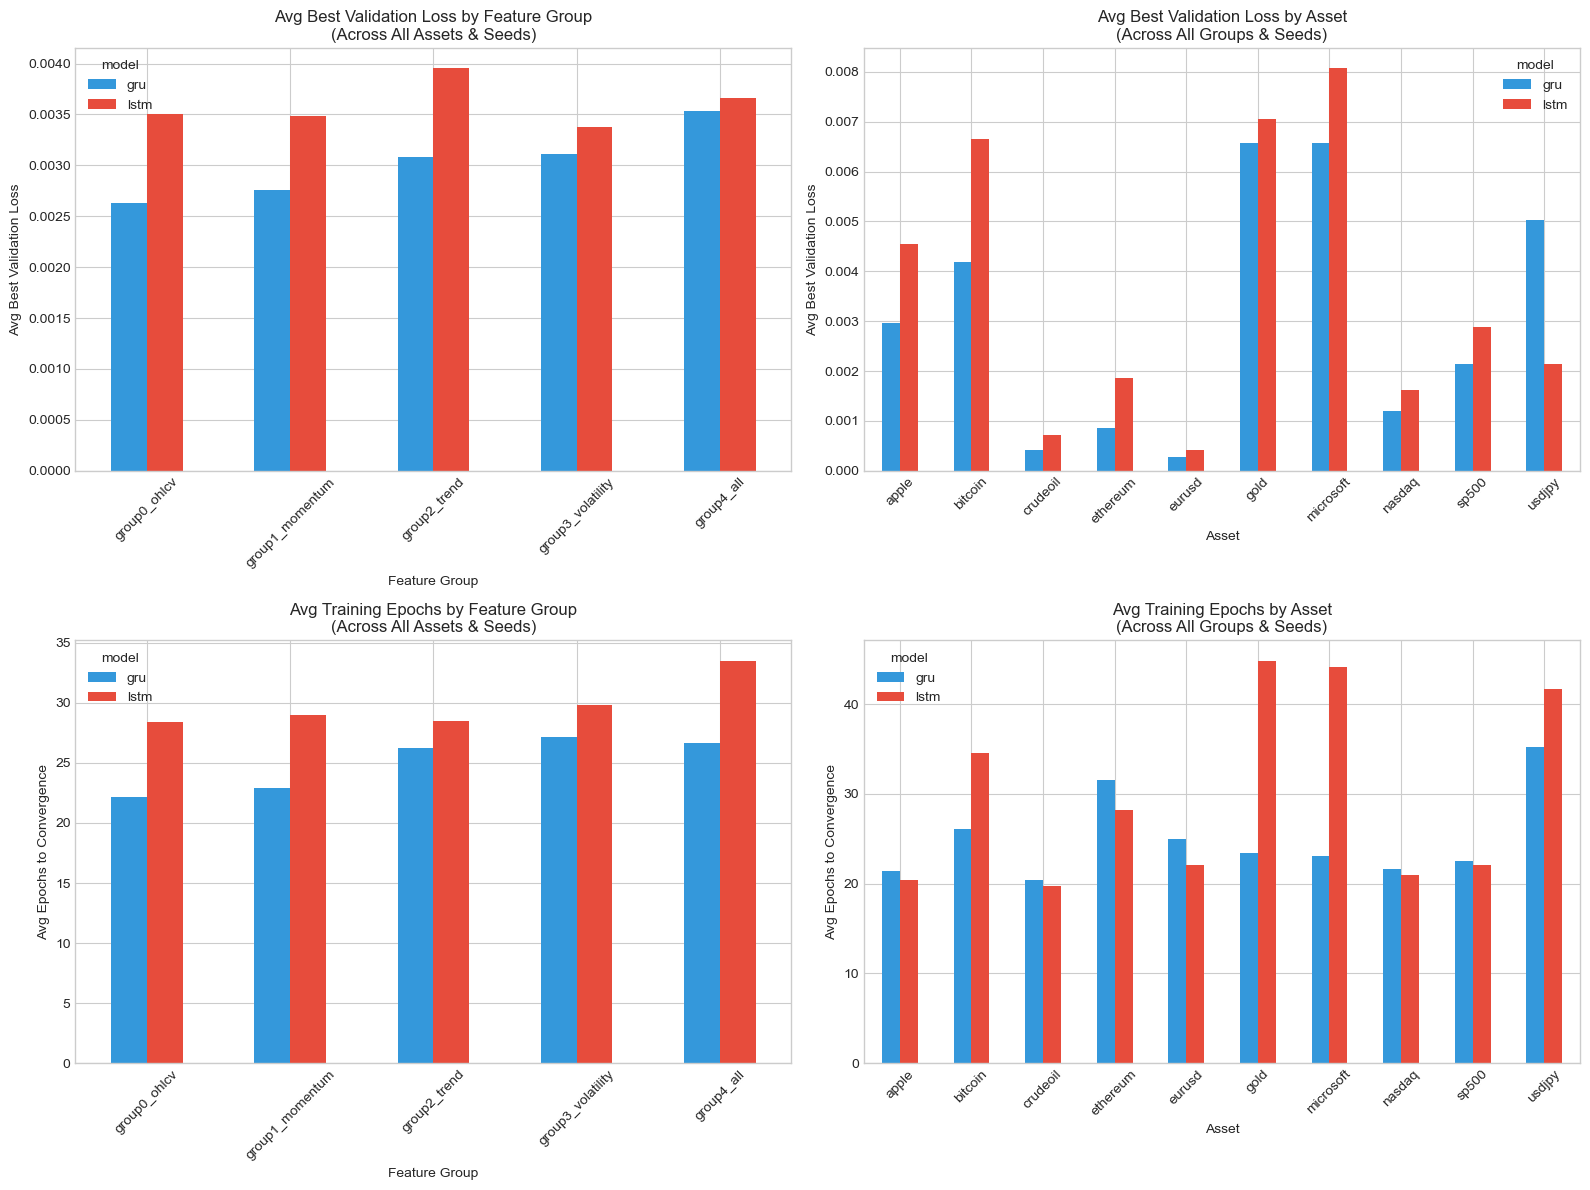

In [8]:
# Compare models across assets and groups (averaged across seeds)
if summary_df.empty:
    print("Skipping plots due to no data.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Best validation loss by group (averaged across assets and seeds)
group_avg = summary_df.groupby(['group', 'model'])['best_val_loss'].mean().unstack()
group_avg.plot(kind='bar', ax=axes[0,0])
axes[0,0].set_xlabel('Feature Group')
axes[0,0].set_ylabel('Avg Best Validation Loss')
axes[0,0].set_title('Avg Best Validation Loss by Feature Group\n(Across All Assets & Seeds)')
axes[0,0].tick_params(axis='x', rotation=45)

# Best validation loss by asset (averaged across groups and seeds)
asset_avg = summary_df.groupby(['asset', 'model'])['best_val_loss'].mean().unstack()
asset_avg.plot(kind='bar', ax=axes[0,1])
axes[0,1].set_xlabel('Asset')
axes[0,1].set_ylabel('Avg Best Validation Loss')
axes[0,1].set_title('Avg Best Validation Loss by Asset\n(Across All Groups & Seeds)')
axes[0,1].tick_params(axis='x', rotation=45)

# Epochs to convergence by group (averaged across assets and seeds)
epochs_group = summary_df.groupby(['group', 'model'])['epochs_trained'].mean().unstack()
epochs_group.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_xlabel('Feature Group')
axes[1,0].set_ylabel('Avg Epochs to Convergence')
axes[1,0].set_title('Avg Training Epochs by Feature Group\n(Across All Assets & Seeds)')
axes[1,0].tick_params(axis='x', rotation=45)

# Epochs to convergence by asset (averaged across groups and seeds)
epochs_asset = summary_df.groupby(['asset', 'model'])['epochs_trained'].mean().unstack()
epochs_asset.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_xlabel('Asset')
axes[1,1].set_ylabel('Avg Epochs to Convergence')
axes[1,1].set_title('Avg Training Epochs by Asset\n(Across All Groups & Seeds)')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Save training summary for each asset and seed combination
for asset in assets:
    for seed in seeds:
        asset_config = config.get_asset_config(asset)
        category = asset_config['category']
        
        # Save per-seed results
        seed_output_dir = config.get_path('results') / category / asset / 'tables' / str(seed)
        seed_output_dir.mkdir(parents=True, exist_ok=True)
        
        seed_summary_dir = seed_output_dir / 'summaries'
        seed_summary_dir.mkdir(parents=True, exist_ok=True)
        
        # Filter results for this asset and seed
        asset_seed_summary = summary_df[
            (summary_df['asset'] == asset) & 
            (summary_df['seed'] == seed)
        ]
        if not asset_seed_summary.empty:
            asset_seed_summary.to_csv(seed_summary_dir / 'training_summary.csv', index=False)
            print(f"Summary saved for {asset} (seed {seed}) to: {seed_summary_dir / 'training_summary.csv'}")

# Overall summary
overall_output_dir = config.get_path('results') / 'overall' / 'tables'
overall_output_dir.mkdir(parents=True, exist_ok=True)
overall_summary_dir = overall_output_dir / 'summaries'
overall_summary_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(overall_summary_dir / 'training_summary.csv', index=False)
print(f"Overall summary saved to: {overall_summary_dir / 'training_summary.csv'}")

Summary saved for crudeoil (seed 42) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables\42\summaries\training_summary.csv
Summary saved for crudeoil (seed 123) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables\123\summaries\training_summary.csv
Summary saved for crudeoil (seed 456) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables\456\summaries\training_summary.csv
Summary saved for crudeoil (seed 739) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables\739\summaries\training_summary.csv
Summary saved for crudeoil (seed 1126) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\crudeoil\tables\1126\summaries\training_summary.csv
Summary saved for gold (seed 42) to: C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\results\commodity\gold\t

In [10]:
print("="*60)
print("MODEL TRAINING SUMMARY")
print("="*60)

if summary_df.empty:
    print("No results to summarize.")
else:
    print(f"\nAssets trained: {len(assets)}")
    print(f"Seeds used: {len(seeds)}")
    print(f"Models trained: {len(training_results)}")
    print(f"Max epochs: {EPOCHS}")
    print(f"Total experiments: {len(assets)} × {len(GROUPS)} × {len(['lstm', 'gru'])} × {len(seeds)} = {len(assets) * len(GROUPS) * 2 * len(seeds)}")

    # Best configurations overall
    best_overall = summary_df.loc[summary_df['best_val_loss'].idxmin()]
    print(f"\nBest overall:")
    print(f"  Asset: {best_overall['asset']}")
    print(f"  Group: {best_overall['group']}")
    print(f"  Model: {best_overall['model']}")
    print(f"  Seed: {best_overall['seed']}")
    print(f"  Best Val Loss: {best_overall['best_val_loss']:.6f}")

    # Best by asset (averaged across seeds)
    print(f"\nBest by asset (avg across seeds):")
    for asset in assets:
        asset_data = summary_df[summary_df['asset'] == asset]
        if not asset_data.empty:
            asset_best = asset_data.loc[asset_data['best_val_loss'].idxmin()]
            print(f"  {asset}: {asset_best['model']} on {asset_best['group']} (avg loss: {asset_data['best_val_loss'].mean():.6f})")

MODEL TRAINING SUMMARY

Assets trained: 10
Seeds used: 3
Models trained: 300
Max epochs: 100
Total experiments: 10 × 5 × 2 × 3 = 300

Best overall:
  Asset: eurusd
  Group: group1_momentum
  Model: gru
  Seed: 123
  Best Val Loss: 0.000244

Best by asset (avg across seeds):
  crudeoil: gru on group0_ohlcv (avg loss: 0.000597)
  gold: lstm on group4_all (avg loss: 0.006829)
  bitcoin: gru on group0_ohlcv (avg loss: 0.005605)
  ethereum: gru on group3_volatility (avg loss: 0.001373)
  apple: gru on group0_ohlcv (avg loss: 0.003985)
  microsoft: gru on group0_ohlcv (avg loss: 0.007777)
  eurusd: gru on group1_momentum (avg loss: 0.000350)
  usdjpy: lstm on group1_momentum (avg loss: 0.003914)
  nasdaq: gru on group0_ohlcv (avg loss: 0.001546)
  sp500: gru on group4_all (avg loss: 0.002805)
